In [1]:
import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_DIR = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
NUM_CLASSES = 7

IMAGE_DIRS = [
    os.path.join(DATA_DIR, "HAM10000_images_part_1"),
    os.path.join(DATA_DIR, "HAM10000_images_part_2")
]

METADATA_PATH = os.path.join(DATA_DIR, "HAM10000_metadata.csv")

CLASS_NAMES = ["akiec", "bcc", "bkl", "df", "mel", "nv", "vasc"]

print("Data directory exists:", os.path.exists(DATA_DIR))
print("Metadata exists:", os.path.exists(METADATA_PATH))
print("Image directories:")
for d in IMAGE_DIRS:
    print(" ", d, "->", os.path.exists(d))

TensorFlow: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Data directory exists: True
Metadata exists: True
Image directories:
  /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1 -> True
  /kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_2 -> True


In [3]:
metadata = pd.read_csv(METADATA_PATH)

print("Metadata shape:", metadata.shape)
print("Columns:", metadata.columns.tolist())
print("\nClass distribution:")
print(metadata["dx"].value_counts().sort_index())

image_lookup = {}

for image_dir in IMAGE_DIRS:
    for filename in os.listdir(image_dir):
        if filename.lower().endswith(".jpg"):
            image_id = os.path.splitext(filename)[0]
            image_lookup[image_id] = os.path.join(image_dir, filename)

metadata["image_path"] = metadata["image_id"].map(image_lookup)

missing = metadata["image_path"].isna().sum()

print("\nImages found:", metadata["image_path"].notna().sum())
print("Missing images:", missing)

assert missing == 0, f"{missing} images could not be located."

df = metadata[["image_id", "dx", "image_path"]].copy()

print("\nFinal dataframe shape:", df.shape)
print("\nFinal class distribution:")
print(df["dx"].value_counts().sort_index())

Metadata shape: (10015, 7)
Columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']

Class distribution:
dx
akiec     327
bcc       514
bkl      1099
df        115
mel      1113
nv       6705
vasc      142
Name: count, dtype: int64

Images found: 10015
Missing images: 0

Final dataframe shape: (10015, 3)

Final class distribution:
dx
akiec     327
bcc       514
bkl      1099
df        115
mel      1113
nv       6705
vasc      142
Name: count, dtype: int64


In [4]:
train_val_df, test_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["dx"],
    random_state=SEED
)

train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.125,
    stratify=train_val_df["dx"],
    random_state=SEED
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))

print("\nTrain distribution:")
print(train_df["dx"].value_counts().sort_index())

print("\nValidation distribution:")
print(val_df["dx"].value_counts().sort_index())

print("\nTest distribution:")
print(test_df["dx"].value_counts().sort_index())

assert len(train_df) + len(val_df) + len(test_df) == len(df)
assert set(train_df["image_id"]).isdisjoint(test_df["image_id"])
assert set(val_df["image_id"]).isdisjoint(test_df["image_id"])
assert set(train_df["image_id"]).isdisjoint(val_df["image_id"])

print("\nNo image overlap between train, validation, and test.")

Train: 7010
Validation: 1002
Test: 2003
Total: 10015

Train distribution:
dx
akiec     229
bcc       360
bkl       769
df         80
mel       779
nv       4693
vasc      100
Name: count, dtype: int64

Validation distribution:
dx
akiec     33
bcc       51
bkl      110
df        12
mel      111
nv       671
vasc      14
Name: count, dtype: int64

Test distribution:
dx
akiec      65
bcc       103
bkl       220
df         23
mel       223
nv       1341
vasc       28
Name: count, dtype: int64

No image overlap between train, validation, and test.


In [7]:
cap = 200

train_cap_parts = []

for class_name, group in train_df.groupby("dx"):
    n_samples = min(len(group), cap)
    sampled = group.sample(n=n_samples, random_state=SEED)
    train_cap_parts.append(sampled)

train_cap_df = pd.concat(train_cap_parts, ignore_index=True)
train_cap_df = train_cap_df.sample(frac=1, random_state=SEED).reset_index(drop=True)

print("Original training size:", len(train_df))
print("Capped training size:", len(train_cap_df))

print("\nExperiment 1 training distribution:")
print(train_cap_df["dx"].value_counts().sort_index())

print("\nValidation size:", len(val_df))
print("Test size:", len(test_df))

assert len(train_cap_df) == 1262
assert len(val_df) == 1002
assert len(test_df) == 2003

assert set(train_cap_df["image_id"]).isdisjoint(val_df["image_id"])
assert set(train_cap_df["image_id"]).isdisjoint(test_df["image_id"])
assert set(val_df["image_id"]).isdisjoint(test_df["image_id"])

print("\nExperiment 1 split verified.")

Original training size: 7010
Capped training size: 1180

Experiment 1 training distribution:
dx
akiec    200
bcc      200
bkl      200
df        80
mel      200
nv       200
vasc     100
Name: count, dtype: int64

Validation size: 1002
Test size: 2003


AssertionError: 

In [8]:
expected_counts = {
    "akiec": 200,
    "bcc": 200,
    "bkl": 200,
    "df": 80,
    "mel": 200,
    "nv": 200,
    "vasc": 100
}

actual_counts = train_cap_df["dx"].value_counts().to_dict()

assert actual_counts == expected_counts
assert len(train_cap_df) == 1180
assert len(val_df) == 1002
assert len(test_df) == 2003

print("Experiment 1 training set:", len(train_cap_df))
print("Validation set:", len(val_df))
print("Untouched test set:", len(test_df))
print("Class distribution verified.")
print("No assertions failed.")

Experiment 1 training set: 1180
Validation set: 1002
Untouched test set: 2003
Class distribution verified.
No assertions failed.


In [9]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.densenet.preprocess_input,
    horizontal_flip=True,
    vertical_flip=True,
    rotation_range=15,
    zoom_range=0.10,
    width_shift_range=0.05,
    height_shift_range=0.05,
    brightness_range=(0.9, 1.1)
)

eval_datagen = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.densenet.preprocess_input
)

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_cap_df,
    x_col="image_path",
    y_col="dx",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=True,
    seed=SEED
)

val_generator = eval_datagen.flow_from_dataframe(
    dataframe=val_df,
    x_col="image_path",
    y_col="dx",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=False
)

test_generator = eval_datagen.flow_from_dataframe(
    dataframe=test_df,
    x_col="image_path",
    y_col="dx",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=False
)

print("\nClass indices:", train_generator.class_indices)
print("Train batches:", len(train_generator))
print("Validation batches:", len(val_generator))
print("Test batches:", len(test_generator))

Found 1180 validated image filenames belonging to 7 classes.
Found 1002 validated image filenames belonging to 7 classes.
Found 2003 validated image filenames belonging to 7 classes.

Class indices: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}
Train batches: 74
Validation batches: 63
Test batches: 126


In [10]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import DenseNet169

base_model = DenseNet169(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.30),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.summary()

print("\nTrainable backbone:", base_model.trainable)
print("Total parameters:", model.count_params())

I0000 00:00:1788759935.995791      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1788759935.998805      58 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


51877672/51877672 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ densenet169 (Functional)        │ (None, 7, 7, 1664)     │    12,642,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1664)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1664)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       426,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │         1,799 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,070,919 (49.86 MB)

 Trainable params: 428,039 (1.63 MB)

 Non-trainable params: 12,642,880 (48.23 MB)


Trainable backbone: False
Total parameters: 13070919


In [11]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

model.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

checkpoint_path = "/kaggle/working/best_densenet169_exp1.keras"

callbacks = [
    ModelCheckpoint(
        checkpoint_path,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("Optimizer: Adam")
print("Initial learning rate: 1e-3")
print("Checkpoint:", checkpoint_path)
print("Backbone frozen:", not base_model.trainable)

Optimizer: Adam
Initial learning rate: 1e-3
Checkpoint: /kaggle/working/best_densenet169_exp1.keras
Backbone frozen: True


In [12]:
EPOCHS = 30

history_exp1 = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

best_val_acc = max(history_exp1.history["val_accuracy"])
best_epoch = np.argmax(history_exp1.history["val_accuracy"]) + 1

print("\nBest validation accuracy:", f"{best_val_acc:.4%}")
print("Best epoch:", best_epoch)

Epoch 1/30
 2/74 ━━━━━━━━━━━━━━━━━━━━ 5s 80ms/step - accuracy: 0.1562 - loss: 2.5318  

I0000 00:00:1788760038.479490     158 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


74/74 ━━━━━━━━━━━━━━━━━━━━ 0s 698ms/step - accuracy: 0.2702 - loss: 2.1360
Epoch 1: val_accuracy improved from None to 0.67764, saving model to /kaggle/working/best_densenet169_exp1.keras

Epoch 1: finished saving model to /kaggle/working/best_densenet169_exp1.keras
74/74 ━━━━━━━━━━━━━━━━━━━━ 146s 1s/step - accuracy: 0.3042 - loss: 1.9145 - val_accuracy: 0.6776 - val_loss: 1.1082 - learning_rate: 0.0010
Epoch 2/30
74/74 ━━━━━━━━━━━━━━━━━━━━ 0s 303ms/step - accuracy: 0.4076 - loss: 1.5016
Epoch 2: val_accuracy did not improve from 0.67764
74/74 ━━━━━━━━━━━━━━━━━━━━ 31s 415ms/step - accuracy: 0.4186 - loss: 1.4632 - val_accuracy: 0.6347 - val_loss: 1.0318 - learning_rate: 0.0010
Epoch 3/30
74/74 ━━━━━━━━━━━━━━━━━━━━ 0s 301ms/step - accuracy: 0.4751 - loss: 1.3368
Epoch 3: val_accuracy improved from 0.67764 to 0.67964, saving model to /kaggle/working/best_densenet169_exp1.keras

Epoch 3: finished saving model to /kaggle/working/best_densenet169_exp1.keras
74/74 ━━━━━━━━━━━━━━━━━━━━ 33s 44

In [13]:
from sklearn.utils.class_weight import compute_class_weight

train_exp2_df = train_df.copy()

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.array(CLASS_NAMES),
    y=train_exp2_df["dx"]
)

class_weights = {
    i: float(weight)
    for i, weight in enumerate(class_weights_array)
}

print("Experiment 2 training size:", len(train_exp2_df))

print("\nTraining distribution:")
print(train_exp2_df["dx"].value_counts().sort_index())

print("\nClass weights:")
for class_name, index in train_generator.class_indices.items():
    print(f"{class_name}: {class_weights[index]:.4f}")

train_generator_exp2 = train_datagen.flow_from_dataframe(
    dataframe=train_exp2_df,
    x_col="image_path",
    y_col="dx",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=True,
    seed=SEED
)

print("\nExperiment 2 generator ready.")
print("Train batches:", len(train_generator_exp2))
print("Validation batches:", len(val_generator))
print("Test batches:", len(test_generator))

Experiment 2 training size: 7010

Training distribution:
dx
akiec     229
bcc       360
bkl       769
df         80
mel       779
nv       4693
vasc      100
Name: count, dtype: int64

Class weights:
akiec: 4.3731
bcc: 2.7817
bkl: 1.3022
df: 12.5179
mel: 1.2855
nv: 0.2134
vasc: 10.0143
Found 7010 validated image filenames belonging to 7 classes.

Experiment 2 generator ready.
Train batches: 439
Validation batches: 63
Test batches: 126


In [14]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import DenseNet169

base_model = DenseNet169(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model_exp2 = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.30),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model_exp2.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

checkpoint_exp2 = "/kaggle/working/best_densenet169_exp2.keras"

callbacks_exp2 = [
    ModelCheckpoint(
        checkpoint_exp2,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=6,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("Experiment 2 model created.")
print("Trainable backbone:", base_model.trainable)
print("Total parameters:", model_exp2.count_params())

Experiment 2 model created.
Trainable backbone: False
Total parameters: 13070919


In [15]:
history_exp2 = model_exp2.fit(
    train_generator_exp2,
    validation_data=val_generator,
    epochs=30,
    class_weight=class_weights,
    callbacks=callbacks_exp2,
    verbose=1
)

best_val_acc_exp2 = max(history_exp2.history["val_accuracy"])
best_epoch_exp2 = np.argmax(history_exp2.history["val_accuracy"]) + 1

print("\nExperiment 2 best validation accuracy:", f"{best_val_acc_exp2:.4%}")
print("Best epoch:", best_epoch_exp2)

Epoch 1/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 448ms/step - accuracy: 0.3010 - loss: 2.1264
Epoch 1: val_accuracy improved from None to 0.52695, saving model to /kaggle/working/best_densenet169_exp2.keras

Epoch 1: finished saving model to /kaggle/working/best_densenet169_exp2.keras
439/439 ━━━━━━━━━━━━━━━━━━━━ 275s 546ms/step - accuracy: 0.3693 - loss: 1.7425 - val_accuracy: 0.5269 - val_loss: 1.3010 - learning_rate: 0.0010
Epoch 2/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 298ms/step - accuracy: 0.4698 - loss: 1.3424
Epoch 2: val_accuracy improved from 0.52695 to 0.57186, saving model to /kaggle/working/best_densenet169_exp2.keras

Epoch 2: finished saving model to /kaggle/working/best_densenet169_exp2.keras
439/439 ━━━━━━━━━━━━━━━━━━━━ 141s 321ms/step - accuracy: 0.4782 - loss: 1.3451 - val_accuracy: 0.5719 - val_loss: 1.0868 - learning_rate: 0.0010
Epoch 3/30
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 304ms/step - accuracy: 0.5019 - loss: 1.3130
Epoch 3: val_accuracy did not improve from 0.57186
439/439 

In [16]:
train_generator_exp3 = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    x_col="image_path",
    y_col="dx",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=True,
    seed=SEED
)

base_model_exp3 = DenseNet169(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model_exp3.trainable = False

model_exp3 = models.Sequential([
    base_model_exp3,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.30),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model_exp3.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

checkpoint_exp3 = "/kaggle/working/best_densenet169_exp3.keras"

callbacks_exp3 = [
    ModelCheckpoint(
        checkpoint_exp3,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("Experiment 3 training images:", len(train_df))
print("Class weights: None")
print("Backbone frozen:", not base_model_exp3.trainable)
print("Validation images:", len(val_df))
print("Untouched test images:", len(test_df))

Found 7010 validated image filenames belonging to 7 classes.
Experiment 3 training images: 7010
Class weights: None
Backbone frozen: True
Validation images: 1002
Untouched test images: 2003


In [17]:
history_exp3 = model_exp3.fit(
    train_generator_exp3,
    validation_data=val_generator,
    epochs=20,
    callbacks=callbacks_exp3,
    verbose=1
)

best_val_acc_exp3 = max(history_exp3.history["val_accuracy"])
best_epoch_exp3 = np.argmax(history_exp3.history["val_accuracy"]) + 1

print("\nExperiment 3 best validation accuracy:", f"{best_val_acc_exp3:.4%}")
print("Best epoch:", best_epoch_exp3)

Epoch 1/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 337ms/step - accuracy: 0.6466 - loss: 1.0920
Epoch 1: val_accuracy improved from None to 0.71457, saving model to /kaggle/working/best_densenet169_exp3.keras

Epoch 1: finished saving model to /kaggle/working/best_densenet169_exp3.keras
439/439 ━━━━━━━━━━━━━━━━━━━━ 227s 435ms/step - accuracy: 0.6812 - loss: 0.9438 - val_accuracy: 0.7146 - val_loss: 0.7271 - learning_rate: 0.0010
Epoch 2/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 305ms/step - accuracy: 0.7160 - loss: 0.7938
Epoch 2: val_accuracy improved from 0.71457 to 0.74251, saving model to /kaggle/working/best_densenet169_exp3.keras

Epoch 2: finished saving model to /kaggle/working/best_densenet169_exp3.keras
439/439 ━━━━━━━━━━━━━━━━━━━━ 144s 328ms/step - accuracy: 0.7185 - loss: 0.7852 - val_accuracy: 0.7425 - val_loss: 0.6863 - learning_rate: 0.0010
Epoch 3/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 305ms/step - accuracy: 0.7251 - loss: 0.7380
Epoch 3: val_accuracy improved from 0.74251 to 0.75349, sav

In [18]:
# Start from the best Experiment 3 weights
model_exp3.load_weights(checkpoint_exp3)

base_model_exp3.trainable = True

# Freeze earlier layers and fine-tune the later layers
fine_tune_from = 400

for layer in base_model_exp3.layers[:fine_tune_from]:
    layer.trainable = False

for layer in base_model_exp3.layers[fine_tune_from:]:
    layer.trainable = True

# Keep BatchNormalization layers frozen for stable fine-tuning
for layer in base_model_exp3.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

trainable_layers = sum(layer.trainable for layer in base_model_exp3.layers)
total_layers = len(base_model_exp3.layers)

print("Total DenseNet169 layers:", total_layers)
print("Trainable backbone layers:", trainable_layers)
print("Frozen backbone layers:", total_layers - trainable_layers)

model_exp3.compile(
    optimizer=Adam(learning_rate=1e-5),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

checkpoint_exp3_ft = "/kaggle/working/best_densenet169_exp3_finetuned.keras"

callbacks_exp3_ft = [
    ModelCheckpoint(
        checkpoint_exp3_ft,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("\nFine-tuning learning rate: 1e-5")
print("Best starting validation accuracy: 79.7405%")
print("Model ready for fine-tuning.")

Total DenseNet169 layers: 595
Trainable backbone layers: 139
Frozen backbone layers: 456

Fine-tuning learning rate: 1e-5
Best starting validation accuracy: 79.7405%
Model ready for fine-tuning.


In [19]:
# Fine-tune the later DenseNet169 layers
history_exp3_ft = model_exp3.fit(
    train_generator_exp3,
    validation_data=val_generator,
    epochs=15,
    callbacks=callbacks_exp3_ft,
    verbose=1
)

best_val_acc_exp3_ft = max(history_exp3_ft.history["val_accuracy"])
best_epoch_exp3_ft = np.argmax(
    history_exp3_ft.history["val_accuracy"]
) + 1

print("\nBest fine-tuned validation accuracy:",
      f"{best_val_acc_exp3_ft:.4%}")
print("Best fine-tuned epoch:", best_epoch_exp3_ft)

Epoch 1/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 376ms/step - accuracy: 0.7842 - loss: 0.5808
Epoch 1: val_accuracy improved from None to 0.79441, saving model to /kaggle/working/best_densenet169_exp3_finetuned.keras

Epoch 1: finished saving model to /kaggle/working/best_densenet169_exp3_finetuned.keras
439/439 ━━━━━━━━━━━━━━━━━━━━ 266s 485ms/step - accuracy: 0.7839 - loss: 0.5915 - val_accuracy: 0.7944 - val_loss: 0.5599 - learning_rate: 1.0000e-05
Epoch 2/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 333ms/step - accuracy: 0.7908 - loss: 0.5738
Epoch 2: val_accuracy did not improve from 0.79441
439/439 ━━━━━━━━━━━━━━━━━━━━ 155s 353ms/step - accuracy: 0.7914 - loss: 0.5741 - val_accuracy: 0.7894 - val_loss: 0.5470 - learning_rate: 1.0000e-05
Epoch 3/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 330ms/step - accuracy: 0.7982 - loss: 0.5479
Epoch 3: val_accuracy improved from 0.79441 to 0.79641, saving model to /kaggle/working/best_densenet169_exp3_finetuned.keras

Epoch 3: finished saving model to /kaggle/workin

In [20]:
# Create a moderately balanced training set by oversampling minority classes
target_per_class = 1200

train_exp4_parts = []

for class_name in CLASS_NAMES:
    class_df = train_df[train_df["dx"] == class_name]

    if len(class_df) < target_per_class:
        sampled = class_df.sample(
            n=target_per_class,
            replace=True,
            random_state=SEED
        )
    else:
        sampled = class_df.sample(
            n=target_per_class,
            random_state=SEED
        )

    train_exp4_parts.append(sampled)

train_exp4_df = pd.concat(
    train_exp4_parts,
    ignore_index=True
).sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

print("Experiment 4 training size:", len(train_exp4_df))
print("\nExperiment 4 training distribution:")
print(train_exp4_df["dx"].value_counts().sort_index())

print("\nValidation size:", len(val_df))
print("Test size:", len(test_df))

assert len(train_exp4_df) == 8400
assert len(val_df) == 1002
assert len(test_df) == 2003

assert set(train_exp4_df["image_id"]).isdisjoint(val_df["image_id"])
assert set(train_exp4_df["image_id"]).isdisjoint(test_df["image_id"])
assert set(val_df["image_id"]).isdisjoint(test_df["image_id"])

print("\nExperiment 4 split verified.")

Experiment 4 training size: 8400

Experiment 4 training distribution:
dx
akiec    1200
bcc      1200
bkl      1200
df       1200
mel      1200
nv       1200
vasc     1200
Name: count, dtype: int64

Validation size: 1002
Test size: 2003

Experiment 4 split verified.


In [21]:
# Experiment 4 training generator
train_generator_exp4 = train_datagen.flow_from_dataframe(
    dataframe=train_exp4_df,
    x_col="image_path",
    y_col="dx",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=True,
    seed=SEED
)

print("\nExperiment 4 generator ready.")
print("Training images:", train_generator_exp4.samples)
print("Training batches:", len(train_generator_exp4))
print("Class indices:", train_generator_exp4.class_indices)

Found 8400 validated image filenames belonging to 7 classes.

Experiment 4 generator ready.
Training images: 8400
Training batches: 525
Class indices: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}


In [22]:
# Experiment 4 model: continue from the best fine-tuned weights
model_exp4 = tf.keras.models.clone_model(model_exp3)
model_exp4.set_weights(model_exp3.get_weights())

base_model_exp4 = model_exp4.layers[0]

print("DenseNet169 layers:", len(base_model_exp4.layers))
print("Starting validation accuracy: 82.2355%")

model_exp4.compile(
    optimizer=Adam(learning_rate=3e-6),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

checkpoint_exp4 = "/kaggle/working/best_densenet169_exp4.keras"

callbacks_exp4 = [
    ModelCheckpoint(
        checkpoint_exp4,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Experiment 4 model ready.")
print("Learning rate: 3e-6")
print("Backbone fine-tuning configuration preserved.")

DenseNet169 layers: 595
Starting validation accuracy: 82.2355%
Experiment 4 model ready.
Learning rate: 3e-6
Backbone fine-tuning configuration preserved.


In [23]:
# Train Experiment 4
history_exp4 = model_exp4.fit(
    train_generator_exp4,
    validation_data=val_generator,
    epochs=15,
    callbacks=callbacks_exp4,
    verbose=1
)

best_val_acc_exp4 = max(history_exp4.history["val_accuracy"])
best_epoch_exp4 = np.argmax(
    history_exp4.history["val_accuracy"]
) + 1

print("\nBest Experiment 4 validation accuracy:",
      f"{best_val_acc_exp4:.4%}")
print("Best Experiment 4 epoch:", best_epoch_exp4)

Epoch 1/15
525/525 ━━━━━━━━━━━━━━━━━━━━ 0s 344ms/step - accuracy: 0.7336 - loss: 0.7237
Epoch 1: val_accuracy improved from None to 0.77445, saving model to /kaggle/working/best_densenet169_exp4.keras

Epoch 1: finished saving model to /kaggle/working/best_densenet169_exp4.keras
525/525 ━━━━━━━━━━━━━━━━━━━━ 288s 440ms/step - accuracy: 0.7333 - loss: 0.7063 - val_accuracy: 0.7745 - val_loss: 0.5781 - learning_rate: 3.0000e-06
Epoch 2/15
525/525 ━━━━━━━━━━━━━━━━━━━━ 0s 344ms/step - accuracy: 0.7504 - loss: 0.6495
Epoch 2: val_accuracy did not improve from 0.77445
525/525 ━━━━━━━━━━━━━━━━━━━━ 190s 362ms/step - accuracy: 0.7535 - loss: 0.6378 - val_accuracy: 0.7655 - val_loss: 0.6317 - learning_rate: 3.0000e-06
Epoch 3/15
525/525 ━━━━━━━━━━━━━━━━━━━━ 0s 346ms/step - accuracy: 0.7614 - loss: 0.6253
Epoch 3: val_accuracy did not improve from 0.77445

Epoch 3: ReduceLROnPlateau reducing learning rate to 9.000000318337698e-07.
525/525 ━━━━━━━━━━━━━━━━━━━━ 191s 364ms/step - accuracy: 0.7656 - l

In [24]:
# Experiment 5: deeper DenseNet169 fine-tuning
model_exp5 = tf.keras.models.clone_model(model_exp3)
model_exp5.load_weights(checkpoint_exp3_ft)

base_model_exp5 = model_exp5.layers[0]
base_model_exp5.trainable = True

# Unfreeze a larger portion of the backbone
fine_tune_from_exp5 = 300

for layer in base_model_exp5.layers[:fine_tune_from_exp5]:
    layer.trainable = False

for layer in base_model_exp5.layers[fine_tune_from_exp5:]:
    layer.trainable = True

# Keep BatchNormalization frozen
for layer in base_model_exp5.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

trainable_layers_exp5 = sum(
    layer.trainable for layer in base_model_exp5.layers
)

print("Total DenseNet169 layers:", len(base_model_exp5.layers))
print("Trainable backbone layers:", trainable_layers_exp5)
print("Frozen backbone layers:",
      len(base_model_exp5.layers) - trainable_layers_exp5)

model_exp5.compile(
    optimizer=Adam(learning_rate=1e-6),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

checkpoint_exp5 = "/kaggle/working/best_densenet169_exp5.keras"

callbacks_exp5 = [
    ModelCheckpoint(
        checkpoint_exp5,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=2,
        min_lr=1e-8,
        verbose=1
    )
]

print("\nStarting weights: best Experiment 3 fine-tuned model")
print("Starting validation accuracy: 82.2355%")
print("Fine-tuning learning rate: 1e-6")
print("Experiment 5 model ready.")

Total DenseNet169 layers: 595
Trainable backbone layers: 211
Frozen backbone layers: 384

Starting weights: best Experiment 3 fine-tuned model
Starting validation accuracy: 82.2355%
Fine-tuning learning rate: 1e-6
Experiment 5 model ready.


In [25]:
# Train Experiment 5
history_exp5 = model_exp5.fit(
    train_generator_exp3,
    validation_data=val_generator,
    epochs=15,
    callbacks=callbacks_exp5,
    verbose=1
)

best_val_acc_exp5 = max(history_exp5.history["val_accuracy"])
best_epoch_exp5 = np.argmax(
    history_exp5.history["val_accuracy"]
) + 1

print("\nBest Experiment 5 validation accuracy:",
      f"{best_val_acc_exp5:.4%}")
print("Best Experiment 5 epoch:", best_epoch_exp5)

Epoch 1/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 435ms/step - accuracy: 0.8472 - loss: 0.4106
Epoch 1: val_accuracy improved from None to 0.81936, saving model to /kaggle/working/best_densenet169_exp5.keras

Epoch 1: finished saving model to /kaggle/working/best_densenet169_exp5.keras
439/439 ━━━━━━━━━━━━━━━━━━━━ 309s 551ms/step - accuracy: 0.8441 - loss: 0.4135 - val_accuracy: 0.8194 - val_loss: 0.4957 - learning_rate: 1.0000e-06
Epoch 2/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 352ms/step - accuracy: 0.8533 - loss: 0.3942
Epoch 2: val_accuracy did not improve from 0.81936
439/439 ━━━━━━━━━━━━━━━━━━━━ 165s 375ms/step - accuracy: 0.8494 - loss: 0.4074 - val_accuracy: 0.8194 - val_loss: 0.4789 - learning_rate: 1.0000e-06
Epoch 3/15
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 352ms/step - accuracy: 0.8438 - loss: 0.4206
Epoch 3: val_accuracy did not improve from 0.81936
439/439 ━━━━━━━━━━━━━━━━━━━━ 164s 374ms/step - accuracy: 0.8451 - loss: 0.4175 - val_accuracy: 0.8174 - val_loss: 0.4899 - learning_rate: 1.0000

In [27]:
# Experiment 6: stronger classification head
from tensorflow.keras import regularizers

base_model_exp6 = DenseNet169(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model_exp6.trainable = False

model_exp6 = models.Sequential([
    base_model_exp6,
    layers.GlobalAveragePooling2D(),
    layers.BatchNormalization(),
    layers.Dropout(0.40),
    layers.Dense(
        512,
        activation="relu",
        kernel_regularizer=regularizers.l2(1e-4)
    ),
    layers.BatchNormalization(),
    layers.Dropout(0.40),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model_exp6.compile(
    optimizer=Adam(learning_rate=1e-3),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

checkpoint_exp6 = "/kaggle/working/best_densenet169_exp6.keras"

callbacks_exp6 = [
    ModelCheckpoint(
        checkpoint_exp6,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

print("Experiment 6 model ready.")
print("DenseNet169 backbone frozen:", not base_model_exp6.trainable)
print("Total parameters:", model_exp6.count_params())
print("Training data:", len(train_df))
print("Validation data:", len(val_df))

Experiment 6 model ready.
DenseNet169 backbone frozen: True
Total parameters: 13507655
Training data: 7010
Validation data: 1002


In [28]:
# Train Experiment 6 classification head
history_exp6 = model_exp6.fit(
    train_generator_exp3,
    validation_data=val_generator,
    epochs=20,
    callbacks=callbacks_exp6,
    verbose=1
)

best_val_acc_exp6 = max(history_exp6.history["val_accuracy"])
best_epoch_exp6 = np.argmax(
    history_exp6.history["val_accuracy"]
) + 1

print("\nBest Experiment 6 validation accuracy:",
      f"{best_val_acc_exp6:.4%}")
print("Best Experiment 6 epoch:", best_epoch_exp6)

Epoch 1/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 407ms/step - accuracy: 0.5160 - loss: 1.8515
Epoch 1: val_accuracy improved from None to 0.73253, saving model to /kaggle/working/best_densenet169_exp6.keras

Epoch 1: finished saving model to /kaggle/working/best_densenet169_exp6.keras
439/439 ━━━━━━━━━━━━━━━━━━━━ 275s 525ms/step - accuracy: 0.6144 - loss: 1.4183 - val_accuracy: 0.7325 - val_loss: 0.8513 - learning_rate: 0.0010
Epoch 2/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 364ms/step - accuracy: 0.7037 - loss: 0.9794
Epoch 2: val_accuracy improved from 0.73253 to 0.76946, saving model to /kaggle/working/best_densenet169_exp6.keras

Epoch 2: finished saving model to /kaggle/working/best_densenet169_exp6.keras
439/439 ━━━━━━━━━━━━━━━━━━━━ 173s 394ms/step - accuracy: 0.7083 - loss: 0.9390 - val_accuracy: 0.7695 - val_loss: 0.7160 - learning_rate: 0.0010
Epoch 3/20
439/439 ━━━━━━━━━━━━━━━━━━━━ 0s 345ms/step - accuracy: 0.7332 - loss: 0.8269
Epoch 3: val_accuracy did not improve from 0.76946
439/439 

In [29]:
# Evaluate the current best model on the validation set
model_exp5.load_weights(checkpoint_exp5)

val_generator.reset()

val_probs = model_exp5.predict(
    val_generator,
    verbose=1
)

val_pred = np.argmax(val_probs, axis=1)
val_true = val_generator.classes

print("\nValidation accuracy:",
      f"{np.mean(val_pred == val_true):.4%}")

print("\nPrediction shape:", val_probs.shape)
print("True labels:", len(val_true))
print("Predicted labels:", len(val_pred))

63/63 ━━━━━━━━━━━━━━━━━━━━ 53s 497ms/step

Validation accuracy: 82.7345%

Prediction shape: (1002, 7)
True labels: 1002
Predicted labels: 1002


In [30]:
from sklearn.metrics import classification_report, confusion_matrix

print("Classification Report — Validation Set\n")

print(
    classification_report(
        val_true,
        val_pred,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

cm_val = confusion_matrix(
    val_true,
    val_pred,
    labels=range(NUM_CLASSES)
)

print("\nConfusion Matrix:")
print(pd.DataFrame(
    cm_val,
    index=[f"True_{c}" for c in CLASS_NAMES],
    columns=[f"Pred_{c}" for c in CLASS_NAMES]
))

Classification Report — Validation Set

              precision    recall  f1-score   support

       akiec     0.6364    0.2121    0.3182        33
         bcc     0.6750    0.5294    0.5934        51
         bkl     0.5685    0.7545    0.6484       110
          df     0.7500    0.5000    0.6000        12
         mel     0.6489    0.5495    0.5951       111
          nv     0.9190    0.9463    0.9325       671
        vasc     0.8333    0.7143    0.7692        14

    accuracy                         0.8273      1002
   macro avg     0.7187    0.6009    0.6367      1002
weighted avg     0.8256    0.8273    0.8202      1002


Confusion Matrix:
            Pred_akiec  Pred_bcc  Pred_bkl  Pred_df  Pred_mel  Pred_nv  \
True_akiec           7         8        14        0         3        1   
True_bcc             1        27         7        0         8        6   
True_bkl             1         3        83        0         8       15   
True_df              0         0         2      

In [31]:
# Experiment 7: targeted moderate oversampling
# Keep all majority-class images and moderately oversample minority classes

oversample_targets = {
    "akiec": 600,
    "bcc": 700,
    "bkl": 1000,
    "df": 400,
    "mel": 1000,
    "nv": 4693,
    "vasc": 400
}

train_exp7_parts = []

for class_name in CLASS_NAMES:
    class_df = train_df[train_df["dx"] == class_name]
    target = oversample_targets[class_name]

    if target > len(class_df):
        sampled = class_df.sample(
            n=target,
            replace=True,
            random_state=SEED
        )
    else:
        sampled = class_df.sample(
            n=target,
            random_state=SEED
        )

    train_exp7_parts.append(sampled)

train_exp7_df = pd.concat(
    train_exp7_parts,
    ignore_index=True
).sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

print("Experiment 7 training size:", len(train_exp7_df))
print("\nExperiment 7 training distribution:")
print(train_exp7_df["dx"].value_counts().sort_index())

print("\nOriginal training size:", len(train_df))
print("Validation size:", len(val_df))
print("Test size:", len(test_df))

assert len(train_exp7_df) == 8793
assert len(val_df) == 1002
assert len(test_df) == 2003

assert set(train_exp7_df["image_id"]).isdisjoint(val_df["image_id"])
assert set(train_exp7_df["image_id"]).isdisjoint(test_df["image_id"])
assert set(val_df["image_id"]).isdisjoint(test_df["image_id"])

print("\nExperiment 7 split verified.")

Experiment 7 training size: 8793

Experiment 7 training distribution:
dx
akiec     600
bcc       700
bkl      1000
df        400
mel      1000
nv       4693
vasc      400
Name: count, dtype: int64

Original training size: 7010
Validation size: 1002
Test size: 2003

Experiment 7 split verified.


In [32]:
train_generator_exp7 = train_datagen.flow_from_dataframe(
    dataframe=train_exp7_df,
    x_col="image_path",
    y_col="dx",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=True,
    seed=SEED
)

print("\nClass indices:", train_generator_exp7.class_indices)
print("Train samples:", train_generator_exp7.samples)
print("Train batches:", len(train_generator_exp7))
print("Validation samples:", val_generator.samples)
print("Test samples:", test_generator.samples)

assert train_generator_exp7.samples == 8793
assert train_generator_exp7.class_indices == train_generator.class_indices

Found 8793 validated image filenames belonging to 7 classes.

Class indices: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}
Train samples: 8793
Train batches: 550
Validation samples: 1002
Test samples: 2003


In [33]:
# Experiment 7: continue from the best Experiment 5 model

model_exp7 = tf.keras.models.clone_model(model_exp5)
model_exp7.load_weights(checkpoint_exp5)

base_model_exp7 = model_exp7.layers[0]

print("Starting validation accuracy:", f"{best_val_acc:.4%}")
print("Backbone trainable before configuration:", base_model_exp7.trainable)

# Keep the same deeper fine-tuning setup that worked best in Experiment 5
base_model_exp7.trainable = True

fine_tune_from_exp7 = 300

for layer in base_model_exp7.layers[:fine_tune_from_exp7]:
    layer.trainable = False

for layer in base_model_exp7.layers[fine_tune_from_exp7:]:
    layer.trainable = True

# Keep BatchNorm layers frozen for stable transfer learning
for layer in base_model_exp7.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

trainable_layers_exp7 = sum(
    layer.trainable for layer in base_model_exp7.layers
)
total_layers_exp7 = len(base_model_exp7.layers)

model_exp7.compile(
    optimizer=Adam(learning_rate=1e-6),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

checkpoint_exp7 = "/kaggle/working/best_densenet169_exp7.keras"

callbacks_exp7 = [
    ModelCheckpoint(
        checkpoint_exp7,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=2,
        min_lr=1e-8,
        verbose=1
    )
]

print("\nExperiment 7 model ready.")
print("Total backbone layers:", total_layers_exp7)
print("Trainable backbone layers:", trainable_layers_exp7)
print("Frozen backbone layers:", total_layers_exp7 - trainable_layers_exp7)
print("Learning rate:", 1e-6)
print("Training samples:", train_generator_exp7.samples)
print("Validation samples:", val_generator.samples)

Starting validation accuracy: 67.9641%
Backbone trainable before configuration: True

Experiment 7 model ready.
Total backbone layers: 595
Trainable backbone layers: 211
Frozen backbone layers: 384
Learning rate: 1e-06
Training samples: 8793
Validation samples: 1002


In [34]:
EPOCHS_EXP7 = 15

history_exp7 = model_exp7.fit(
    train_generator_exp7,
    validation_data=val_generator,
    epochs=EPOCHS_EXP7,
    callbacks=callbacks_exp7,
    verbose=1
)

best_val_acc_exp7 = max(history_exp7.history["val_accuracy"])
best_epoch_exp7 = np.argmax(history_exp7.history["val_accuracy"]) + 1

print("\nExperiment 7 Results")
print("Best validation accuracy:", f"{best_val_acc_exp7:.4%}")
print("Best epoch:", best_epoch_exp7)
print("Previous best:", "82.7345%")
print(
    "Change:",
    f"{(best_val_acc_exp7 - 0.827345) * 100:+.2f} percentage points"
)

Epoch 1/15
550/550 ━━━━━━━━━━━━━━━━━━━━ 0s 432ms/step - accuracy: 0.8127 - loss: 0.4997
Epoch 1: val_accuracy improved from None to 0.81637, saving model to /kaggle/working/best_densenet169_exp7.keras

Epoch 1: finished saving model to /kaggle/working/best_densenet169_exp7.keras
550/550 ━━━━━━━━━━━━━━━━━━━━ 354s 524ms/step - accuracy: 0.8133 - loss: 0.4935 - val_accuracy: 0.8164 - val_loss: 0.4797 - learning_rate: 1.0000e-06
Epoch 2/15
550/550 ━━━━━━━━━━━━━━━━━━━━ 0s 358ms/step - accuracy: 0.8218 - loss: 0.4818
Epoch 2: val_accuracy improved from 0.81637 to 0.81936, saving model to /kaggle/working/best_densenet169_exp7.keras

Epoch 2: finished saving model to /kaggle/working/best_densenet169_exp7.keras
550/550 ━━━━━━━━━━━━━━━━━━━━ 210s 381ms/step - accuracy: 0.8199 - loss: 0.4790 - val_accuracy: 0.8194 - val_loss: 0.4735 - learning_rate: 1.0000e-06
Epoch 3/15
550/550 ━━━━━━━━━━━━━━━━━━━━ 0s 373ms/step - accuracy: 0.8163 - loss: 0.4858
Epoch 3: val_accuracy did not improve from 0.81936


In [35]:
from sklearn.metrics import classification_report, confusion_matrix

model_exp7.load_weights(checkpoint_exp7)

val_generator.reset()
val_probs_exp7 = model_exp7.predict(val_generator, verbose=1)
val_pred_exp7 = np.argmax(val_probs_exp7, axis=1)
val_true_exp7 = val_generator.classes

print("Experiment 7 Validation Accuracy:",
      f"{np.mean(val_pred_exp7 == val_true_exp7):.4%}")

print("\nClassification Report — Experiment 7\n")

print(
    classification_report(
        val_true_exp7,
        val_pred_exp7,
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    )
)

cm_val_exp7 = confusion_matrix(
    val_true_exp7,
    val_pred_exp7,
    labels=range(NUM_CLASSES)
)

print("\nConfusion Matrix:")
print(pd.DataFrame(
    cm_val_exp7,
    index=[f"True_{c}" for c in CLASS_NAMES],
    columns=[f"Pred_{c}" for c in CLASS_NAMES]
))

63/63 ━━━━━━━━━━━━━━━━━━━━ 55s 503ms/step
Experiment 7 Validation Accuracy: 83.4331%

Classification Report — Experiment 7

              precision    recall  f1-score   support

       akiec     0.6000    0.2727    0.3750        33
         bcc     0.6275    0.6275    0.6275        51
         bkl     0.6529    0.7182    0.6840       110
          df     0.5625    0.7500    0.6429        12
         mel     0.6436    0.5856    0.6132       111
          nv     0.9225    0.9404    0.9314       671
        vasc     0.7857    0.7857    0.7857        14

    accuracy                         0.8343      1002
   macro avg     0.6849    0.6686    0.6657      1002
weighted avg     0.8302    0.8343    0.8297      1002


Confusion Matrix:
            Pred_akiec  Pred_bcc  Pred_bkl  Pred_df  Pred_mel  Pred_nv  \
True_akiec           9        11         8        0         3        2   
True_bcc             2        32         4        1         5        5   
True_bkl             1         5      

In [36]:
# Experiment 8: focal loss starting from the best Experiment 7 weights

def categorical_focal_loss(gamma=1.5):
    def loss_fn(y_true, y_pred):
        y_pred = tf.clip_by_value(
            y_pred,
            tf.keras.backend.epsilon(),
            1.0 - tf.keras.backend.epsilon()
        )

        cross_entropy = -y_true * tf.math.log(y_pred)
        focal_factor = tf.pow(1.0 - y_pred, gamma)

        return tf.reduce_sum(
            focal_factor * cross_entropy,
            axis=-1
        )

    return loss_fn


model_exp8 = tf.keras.models.clone_model(model_exp7)
model_exp8.load_weights(checkpoint_exp7)

base_model_exp8 = model_exp8.layers[0]
base_model_exp8.trainable = True

fine_tune_from_exp8 = 300

for layer in base_model_exp8.layers[:fine_tune_from_exp8]:
    layer.trainable = False

for layer in base_model_exp8.layers[fine_tune_from_exp8:]:
    layer.trainable = True

for layer in base_model_exp8.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model_exp8.compile(
    optimizer=Adam(learning_rate=3e-7),
    loss=categorical_focal_loss(gamma=1.5),
    metrics=["accuracy"]
)

checkpoint_exp8 = "/kaggle/working/best_densenet169_exp8.keras"

callbacks_exp8 = [
    ModelCheckpoint(
        checkpoint_exp8,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=2,
        min_lr=1e-9,
        verbose=1
    )
]

print("Experiment 8 model ready.")
print("Starting weights: Experiment 7")
print("Starting validation accuracy: 83.4331%")
print("Fine-tuning from layer:", fine_tune_from_exp8)
print("Learning rate:", 3e-7)
print("Focal gamma:", 1.5)

Experiment 8 model ready.
Starting weights: Experiment 7
Starting validation accuracy: 83.4331%
Fine-tuning from layer: 300
Learning rate: 3e-07
Focal gamma: 1.5


In [37]:
EPOCHS_EXP8 = 12

history_exp8 = model_exp8.fit(
    train_generator_exp7,
    validation_data=val_generator,
    epochs=EPOCHS_EXP8,
    callbacks=callbacks_exp8,
    verbose=1
)

best_val_acc_exp8 = max(history_exp8.history["val_accuracy"])
best_epoch_exp8 = np.argmax(history_exp8.history["val_accuracy"]) + 1

print("\nExperiment 8 Results")
print("Best validation accuracy:", f"{best_val_acc_exp8:.4%}")
print("Best epoch:", best_epoch_exp8)
print("Previous best:", "83.4331%")
print(
    "Change:",
    f"{(best_val_acc_exp8 - 0.834331) * 100:+.2f} percentage points"
)

Epoch 1/12
550/550 ━━━━━━━━━━━━━━━━━━━━ 0s 417ms/step - accuracy: 0.8304 - loss: 0.2805
Epoch 1: val_accuracy improved from None to 0.81238, saving model to /kaggle/working/best_densenet169_exp8.keras

Epoch 1: finished saving model to /kaggle/working/best_densenet169_exp8.keras
550/550 ━━━━━━━━━━━━━━━━━━━━ 346s 509ms/step - accuracy: 0.8265 - loss: 0.2807 - val_accuracy: 0.8124 - val_loss: 0.2922 - learning_rate: 3.0000e-07
Epoch 2/12
550/550 ━━━━━━━━━━━━━━━━━━━━ 0s 349ms/step - accuracy: 0.8256 - loss: 0.2675
Epoch 2: val_accuracy improved from 0.81238 to 0.81337, saving model to /kaggle/working/best_densenet169_exp8.keras

Epoch 2: finished saving model to /kaggle/working/best_densenet169_exp8.keras
550/550 ━━━━━━━━━━━━━━━━━━━━ 205s 372ms/step - accuracy: 0.8244 - loss: 0.2695 - val_accuracy: 0.8134 - val_loss: 0.2856 - learning_rate: 3.0000e-07
Epoch 3/12
550/550 ━━━━━━━━━━━━━━━━━━━━ 0s 347ms/step - accuracy: 0.8301 - loss: 0.2594
Epoch 3: val_accuracy improved from 0.81337 to 0.81

In [38]:
# Experiment 9: conservative augmentation

train_datagen_exp9 = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.densenet.preprocess_input,
    horizontal_flip=True,
    vertical_flip=True,
    rotation_range=10,
    zoom_range=0.05
)

train_generator_exp9 = train_datagen_exp9.flow_from_dataframe(
    dataframe=train_exp7_df,
    x_col="image_path",
    y_col="dx",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=True,
    seed=SEED
)

print("\nExperiment 9 generator ready.")
print("Training samples:", train_generator_exp9.samples)
print("Training batches:", len(train_generator_exp9))
print("Validation samples:", val_generator.samples)
print("Test samples:", test_generator.samples)

assert train_generator_exp9.samples == 8793
assert train_generator_exp9.class_indices == train_generator.class_indices

Found 8793 validated image filenames belonging to 7 classes.

Experiment 9 generator ready.
Training samples: 8793
Training batches: 550
Validation samples: 1002
Test samples: 2003


In [39]:
# Experiment 9: fine-tune the best Experiment 7 model
# using conservative augmentation

model_exp9 = tf.keras.models.clone_model(model_exp7)
model_exp9.load_weights(checkpoint_exp7)

base_model_exp9 = model_exp9.layers[0]
base_model_exp9.trainable = True

fine_tune_from_exp9 = 300

for layer in base_model_exp9.layers[:fine_tune_from_exp9]:
    layer.trainable = False

for layer in base_model_exp9.layers[fine_tune_from_exp9:]:
    layer.trainable = True

# Keep BatchNorm frozen for stable fine-tuning
for layer in base_model_exp9.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model_exp9.compile(
    optimizer=Adam(learning_rate=1e-6),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

checkpoint_exp9 = "/kaggle/working/best_densenet169_exp9.keras"

callbacks_exp9 = [
    ModelCheckpoint(
        checkpoint_exp9,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=2,
        min_lr=1e-8,
        verbose=1
    )
]

trainable_layers_exp9 = sum(
    layer.trainable for layer in base_model_exp9.layers
)

print("Experiment 9 model ready.")
print("Starting weights: Experiment 7")
print("Starting validation accuracy: 83.4331%")
print("Trainable backbone layers:", trainable_layers_exp9)
print("Frozen backbone layers:",
      len(base_model_exp9.layers) - trainable_layers_exp9)
print("Learning rate:", 1e-6)

Experiment 9 model ready.
Starting weights: Experiment 7
Starting validation accuracy: 83.4331%
Trainable backbone layers: 211
Frozen backbone layers: 384
Learning rate: 1e-06


In [40]:
EPOCHS_EXP9 = 20

history_exp9 = model_exp9.fit(
    train_generator_exp9,
    validation_data=val_generator,
    epochs=EPOCHS_EXP9,
    callbacks=callbacks_exp9,
    verbose=1
)

best_val_acc_exp9 = max(history_exp9.history["val_accuracy"])
best_epoch_exp9 = np.argmax(history_exp9.history["val_accuracy"]) + 1

print("\nExperiment 9 Results")
print("Best validation accuracy:", f"{best_val_acc_exp9:.4%}")
print("Best epoch:", best_epoch_exp9)
print("Previous best:", "83.4331%")
print(
    "Change:",
    f"{(best_val_acc_exp9 - 0.834331) * 100:+.2f} percentage points"
)

Epoch 1/20
550/550 ━━━━━━━━━━━━━━━━━━━━ 0s 381ms/step - accuracy: 0.8228 - loss: 0.4659
Epoch 1: val_accuracy improved from None to 0.82735, saving model to /kaggle/working/best_densenet169_exp9.keras

Epoch 1: finished saving model to /kaggle/working/best_densenet169_exp9.keras
550/550 ━━━━━━━━━━━━━━━━━━━━ 327s 472ms/step - accuracy: 0.8301 - loss: 0.4418 - val_accuracy: 0.8273 - val_loss: 0.4659 - learning_rate: 1.0000e-06
Epoch 2/20
550/550 ━━━━━━━━━━━━━━━━━━━━ 0s 315ms/step - accuracy: 0.8260 - loss: 0.4488
Epoch 2: val_accuracy did not improve from 0.82735
550/550 ━━━━━━━━━━━━━━━━━━━━ 183s 332ms/step - accuracy: 0.8325 - loss: 0.4319 - val_accuracy: 0.8124 - val_loss: 0.4836 - learning_rate: 1.0000e-06
Epoch 3/20
550/550 ━━━━━━━━━━━━━━━━━━━━ 0s 314ms/step - accuracy: 0.8314 - loss: 0.4446
Epoch 3: val_accuracy improved from 0.82735 to 0.82934, saving model to /kaggle/working/best_densenet169_exp9.keras

Epoch 3: finished saving model to /kaggle/working/best_densenet169_exp9.keras


In [41]:
# Experiment 10: label smoothing from the best Experiment 7 weights

model_exp10 = tf.keras.models.clone_model(model_exp7)
model_exp10.load_weights(checkpoint_exp7)

base_model_exp10 = model_exp10.layers[0]
base_model_exp10.trainable = True

fine_tune_from_exp10 = 300

for layer in base_model_exp10.layers[:fine_tune_from_exp10]:
    layer.trainable = False

for layer in base_model_exp10.layers[fine_tune_from_exp10:]:
    layer.trainable = True

for layer in base_model_exp10.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model_exp10.compile(
    optimizer=Adam(learning_rate=1e-6),
    loss=tf.keras.losses.CategoricalCrossentropy(
        label_smoothing=0.05
    ),
    metrics=["accuracy"]
)

checkpoint_exp10 = "/kaggle/working/best_densenet169_exp10.keras"

callbacks_exp10 = [
    ModelCheckpoint(
        checkpoint_exp10,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=2,
        min_lr=1e-8,
        verbose=1
    )
]

trainable_layers_exp10 = sum(
    layer.trainable for layer in base_model_exp10.layers
)

print("Experiment 10 model ready.")
print("Starting weights: Experiment 7")
print("Starting validation accuracy: 83.4331%")
print("Trainable backbone layers:", trainable_layers_exp10)
print("Frozen backbone layers:",
      len(base_model_exp10.layers) - trainable_layers_exp10)
print("Learning rate:", 1e-6)
print("Label smoothing:", 0.05)

Experiment 10 model ready.
Starting weights: Experiment 7
Starting validation accuracy: 83.4331%
Trainable backbone layers: 211
Frozen backbone layers: 384
Learning rate: 1e-06
Label smoothing: 0.05


In [42]:
EPOCHS_EXP10 = 20

history_exp10 = model_exp10.fit(
    train_generator_exp7,
    validation_data=val_generator,
    epochs=EPOCHS_EXP10,
    callbacks=callbacks_exp10,
    verbose=1
)

best_val_acc_exp10 = max(history_exp10.history["val_accuracy"])
best_epoch_exp10 = np.argmax(history_exp10.history["val_accuracy"]) + 1

print("\nExperiment 10 Results")
print("Best validation accuracy:", f"{best_val_acc_exp10:.4%}")
print("Best epoch:", best_epoch_exp10)
print("Previous best:", "83.4331%")
print(
    "Change:",
    f"{(best_val_acc_exp10 - 0.834331) * 100:+.2f} percentage points"
)

Epoch 1/20
550/550 ━━━━━━━━━━━━━━━━━━━━ 0s 417ms/step - accuracy: 0.8205 - loss: 0.8234
Epoch 1: val_accuracy improved from None to 0.82834, saving model to /kaggle/working/best_densenet169_exp10.keras

Epoch 1: finished saving model to /kaggle/working/best_densenet169_exp10.keras
550/550 ━━━━━━━━━━━━━━━━━━━━ 346s 509ms/step - accuracy: 0.8216 - loss: 0.8000 - val_accuracy: 0.8283 - val_loss: 0.7701 - learning_rate: 1.0000e-06
Epoch 2/20
550/550 ━━━━━━━━━━━━━━━━━━━━ 0s 353ms/step - accuracy: 0.8169 - loss: 0.7750
Epoch 2: val_accuracy did not improve from 0.82834
550/550 ━━━━━━━━━━━━━━━━━━━━ 204s 371ms/step - accuracy: 0.8228 - loss: 0.7646 - val_accuracy: 0.8134 - val_loss: 0.7631 - learning_rate: 1.0000e-06
Epoch 3/20
550/550 ━━━━━━━━━━━━━━━━━━━━ 0s 347ms/step - accuracy: 0.8261 - loss: 0.7454
Epoch 3: val_accuracy did not improve from 0.82834
550/550 ━━━━━━━━━━━━━━━━━━━━ 200s 364ms/step - accuracy: 0.8294 - loss: 0.7404 - val_accuracy: 0.8244 - val_loss: 0.7419 - learning_rate: 1.00

In [44]:
# Analyze the most common validation misclassifications

model_exp7.load_weights(checkpoint_exp7)

val_generator.reset()
val_probs_exp7 = model_exp7.predict(val_generator, verbose=1)

val_pred_exp7 = np.argmax(val_probs_exp7, axis=1)
val_true_exp7 = np.asarray(val_generator.classes)

error_mask = val_pred_exp7 != val_true_exp7

error_df = val_df.loc[error_mask].copy()

error_df["true_class"] = [
    CLASS_NAMES[int(i)] for i in val_true_exp7[error_mask]
]

error_df["pred_class"] = [
    CLASS_NAMES[int(i)] for i in val_pred_exp7[error_mask]
]

error_df["confidence"] = np.max(
    val_probs_exp7[error_mask],
    axis=1
)

print("Total validation samples:", len(val_df))
print("Misclassified samples:", len(error_df))

print(
    "Validation accuracy:",
    f"{1 - len(error_df) / len(val_df):.4%}"
)

print("\nMost common misclassification pairs:")
print(
    error_df.groupby(
        ["true_class", "pred_class"]
    ).size().sort_values(ascending=False).head(15)
)

print(
    "\nAverage confidence on misclassified samples:",
    f"{error_df['confidence'].mean():.4f}"
)

print("\nLowest-confidence misclassified samples:")
print(
    error_df[
        ["image_id", "true_class", "pred_class", "confidence"]
    ]
    .sort_values("confidence")
    .head(15)
    .to_string(index=False)
)

63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 145ms/step
Total validation samples: 1002
Misclassified samples: 166
Validation accuracy: 83.4331%

Most common misclassification pairs:
true_class  pred_class
mel         nv            28
nv          mel           17
            bkl           15
bkl         nv            15
mel         bkl           13
akiec       bcc           11
bkl         mel           10
akiec       bkl            8
nv          df             5
bcc         mel            5
bkl         bcc            5
bcc         nv             5
            bkl            4
akiec       mel            3
mel         akiec          2
dtype: int64

Average confidence on misclassified samples: 0.5904

Lowest-confidence misclassified samples:
    image_id true_class pred_class  confidence
ISIC_0024403        bcc         nv    0.269722
ISIC_0024562      akiec         nv    0.276851
ISIC_0026337        bcc        mel    0.310139
ISIC_0027397         nv         df    0.313715
ISIC_0031986        bcc      aki

In [45]:
# Experiment 11: stronger augmentation for difficult classes

train_exp11_parts = []

target_exp11 = {
    "akiec": 800,
    "bcc": 700,
    "bkl": 1000,
    "df": 400,
    "mel": 1400,
    "nv": 4693,
    "vasc": 400
}

for class_name in CLASS_NAMES:
    class_df = train_df[train_df["dx"] == class_name]
    target = target_exp11[class_name]

    if target > len(class_df):
        sampled = class_df.sample(
            n=target,
            replace=True,
            random_state=SEED
        )
    else:
        sampled = class_df.sample(
            n=target,
            random_state=SEED
        )

    train_exp11_parts.append(sampled)

train_exp11_df = pd.concat(
    train_exp11_parts,
    ignore_index=True
).sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)

print("Experiment 11 training size:", len(train_exp11_df))
print("\nExperiment 11 training distribution:")
print(train_exp11_df["dx"].value_counts().sort_index())

assert len(train_exp11_df) == 9393
assert len(val_df) == 1002
assert len(test_df) == 2003

assert set(train_exp11_df["image_id"]).isdisjoint(val_df["image_id"])
assert set(train_exp11_df["image_id"]).isdisjoint(test_df["image_id"])
assert set(val_df["image_id"]).isdisjoint(test_df["image_id"])

print("\nExperiment 11 split verified.")

Experiment 11 training size: 9393

Experiment 11 training distribution:
dx
akiec     800
bcc       700
bkl      1000
df        400
mel      1400
nv       4693
vasc      400
Name: count, dtype: int64

Experiment 11 split verified.


In [46]:
train_datagen_exp11 = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.densenet.preprocess_input,
    horizontal_flip=True,
    vertical_flip=True,
    rotation_range=20,
    zoom_range=0.10,
    width_shift_range=0.05,
    height_shift_range=0.05
)

train_generator_exp11 = train_datagen_exp11.flow_from_dataframe(
    dataframe=train_exp11_df,
    x_col="image_path",
    y_col="dx",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=True,
    seed=SEED
)

print("Experiment 11 batches:", len(train_generator_exp11))
print("Class indices:", train_generator_exp11.class_indices)

Found 9393 validated image filenames belonging to 7 classes.
Experiment 11 batches: 588
Class indices: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}


In [47]:
model_exp11 = tf.keras.models.clone_model(model_exp7)
model_exp11.load_weights(checkpoint_exp7)

base_model_exp11 = model_exp11.layers[0]
base_model_exp11.trainable = True

fine_tune_from_exp11 = 300

for layer in base_model_exp11.layers[:fine_tune_from_exp11]:
    layer.trainable = False

for layer in base_model_exp11.layers[fine_tune_from_exp11:]:
    layer.trainable = True

for layer in base_model_exp11.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

trainable_layers_exp11 = sum(
    layer.trainable for layer in base_model_exp11.layers
)

total_layers_exp11 = len(base_model_exp11.layers)

model_exp11.compile(
    optimizer=Adam(learning_rate=1e-6),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

checkpoint_exp11 = "/kaggle/working/best_densenet169_exp11.keras"

callbacks_exp11 = [
    ModelCheckpoint(
        checkpoint_exp11,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=2,
        min_lr=1e-8,
        verbose=1
    )
]

print("Experiment 11 model ready.")
print("Total DenseNet layers:", total_layers_exp11)
print("Trainable backbone layers:", trainable_layers_exp11)
print("Frozen backbone layers:", total_layers_exp11 - trainable_layers_exp11)
print("Learning rate:", 1e-6)
print("Starting validation accuracy: 83.4331%")

Experiment 11 model ready.
Total DenseNet layers: 595
Trainable backbone layers: 211
Frozen backbone layers: 384
Learning rate: 1e-06
Starting validation accuracy: 83.4331%


In [48]:
history_exp11 = model_exp11.fit(
    train_generator_exp11,
    validation_data=val_generator,
    epochs=20,
    callbacks=callbacks_exp11,
    verbose=1
)

best_val_acc_exp11 = max(history_exp11.history["val_accuracy"])
best_epoch_exp11 = np.argmax(
    history_exp11.history["val_accuracy"]
) + 1

print("\nExperiment 11 results")
print("Best validation accuracy:", f"{best_val_acc_exp11:.4%}")
print("Best epoch:", best_epoch_exp11)
print("Previous best (Exp7): 83.4331%")
print(
    "Improvement:",
    f"{(best_val_acc_exp11 - 0.834331) * 100:+.2f} percentage points"
)

Epoch 1/20
588/588 ━━━━━━━━━━━━━━━━━━━━ 0s 396ms/step - accuracy: 0.8084 - loss: 0.4958
Epoch 1: val_accuracy improved from None to 0.82036, saving model to /kaggle/working/best_densenet169_exp11.keras

Epoch 1: finished saving model to /kaggle/working/best_densenet169_exp11.keras
588/588 ━━━━━━━━━━━━━━━━━━━━ 350s 483ms/step - accuracy: 0.8148 - loss: 0.4826 - val_accuracy: 0.8204 - val_loss: 0.4718 - learning_rate: 1.0000e-06
Epoch 2/20
588/588 ━━━━━━━━━━━━━━━━━━━━ 0s 324ms/step - accuracy: 0.8103 - loss: 0.5030
Epoch 2: val_accuracy did not improve from 0.82036
588/588 ━━━━━━━━━━━━━━━━━━━━ 201s 341ms/step - accuracy: 0.8135 - loss: 0.4874 - val_accuracy: 0.8194 - val_loss: 0.4760 - learning_rate: 1.0000e-06
Epoch 3/20
588/588 ━━━━━━━━━━━━━━━━━━━━ 0s 322ms/step - accuracy: 0.8164 - loss: 0.4791
Epoch 3: val_accuracy did not improve from 0.82036

Epoch 3: ReduceLROnPlateau reducing learning rate to 2.999999992425728e-07.
588/588 ━━━━━━━━━━━━━━━━━━━━ 200s 340ms/step - accuracy: 0.8140 -

In [49]:
print("Experiment 7 learning history")

for epoch, (acc, val_acc, loss, val_loss) in enumerate(
    zip(
        history_exp7.history["accuracy"],
        history_exp7.history["val_accuracy"],
        history_exp7.history["loss"],
        history_exp7.history["val_loss"]
    ),
    start=1
):
    print(
        f"Epoch {epoch:02d}: "
        f"train_acc={acc:.4f}, "
        f"val_acc={val_acc:.4f}, "
        f"train_loss={loss:.4f}, "
        f"val_loss={val_loss:.4f}"
    )

best_idx = np.argmax(history_exp7.history["val_accuracy"])

print("\nBest epoch:", best_idx + 1)
print(
    "Best validation accuracy:",
    f"{history_exp7.history['val_accuracy'][best_idx]:.4%}"
)

Experiment 7 learning history
Epoch 01: train_acc=0.8133, val_acc=0.8164, train_loss=0.4935, val_loss=0.4797
Epoch 02: train_acc=0.8199, val_acc=0.8194, train_loss=0.4790, val_loss=0.4735
Epoch 03: train_acc=0.8226, val_acc=0.8164, train_loss=0.4798, val_loss=0.4812
Epoch 04: train_acc=0.8266, val_acc=0.8343, train_loss=0.4626, val_loss=0.4651
Epoch 05: train_acc=0.8271, val_acc=0.8194, train_loss=0.4588, val_loss=0.4732
Epoch 06: train_acc=0.8285, val_acc=0.8144, train_loss=0.4516, val_loss=0.4846
Epoch 07: train_acc=0.8340, val_acc=0.8253, train_loss=0.4375, val_loss=0.4713
Epoch 08: train_acc=0.8412, val_acc=0.8194, train_loss=0.4246, val_loss=0.4753
Epoch 09: train_acc=0.8350, val_acc=0.8224, train_loss=0.4372, val_loss=0.4727

Best epoch: 4
Best validation accuracy: 83.4331%


In [50]:
model_exp12 = tf.keras.models.clone_model(model_exp7)
model_exp12.load_weights(checkpoint_exp7)

base_model_exp12 = model_exp12.layers[0]
base_model_exp12.trainable = True

fine_tune_from_exp12 = 300

for layer in base_model_exp12.layers[:fine_tune_from_exp12]:
    layer.trainable = False

for layer in base_model_exp12.layers[fine_tune_from_exp12:]:
    layer.trainable = True

for layer in base_model_exp12.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model_exp12.compile(
    optimizer=Adam(learning_rate=3e-7),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

checkpoint_exp12 = "/kaggle/working/best_densenet169_exp12.keras"

callbacks_exp12 = [
    ModelCheckpoint(
        checkpoint_exp12,
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_accuracy",
        mode="max",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.3,
        patience=2,
        min_lr=1e-9,
        verbose=1
    )
]

print("Experiment 12 model ready.")
print("Trainable backbone layers:",
      sum(layer.trainable for layer in base_model_exp12.layers))
print("Frozen backbone layers:",
      sum(not layer.trainable for layer in base_model_exp12.layers))
print("Learning rate:", 3e-7)
print("Starting validation accuracy: 83.4331%")

Experiment 12 model ready.
Trainable backbone layers: 211
Frozen backbone layers: 384
Learning rate: 3e-07
Starting validation accuracy: 83.4331%


In [51]:
history_exp12 = model_exp12.fit(
    train_generator_exp7,
    validation_data=val_generator,
    epochs=20,
    callbacks=callbacks_exp12,
    verbose=1
)

best_val_acc_exp12 = max(
    history_exp12.history["val_accuracy"]
)

best_epoch_exp12 = (
    np.argmax(history_exp12.history["val_accuracy"]) + 1
)

print("\nExperiment 12 results")
print(
    "Best validation accuracy:",
    f"{best_val_acc_exp12:.4%}"
)
print("Best epoch:", best_epoch_exp12)
print("Previous best (Exp7): 83.4331%")
print(
    "Improvement:",
    f"{(best_val_acc_exp12 - 0.834331) * 100:+.2f} percentage points"
)

Epoch 1/20
550/550 ━━━━━━━━━━━━━━━━━━━━ 0s 420ms/step - accuracy: 0.8347 - loss: 0.4529
Epoch 1: val_accuracy improved from None to 0.81537, saving model to /kaggle/working/best_densenet169_exp12.keras

Epoch 1: finished saving model to /kaggle/working/best_densenet169_exp12.keras
550/550 ━━━━━━━━━━━━━━━━━━━━ 348s 515ms/step - accuracy: 0.8319 - loss: 0.4523 - val_accuracy: 0.8154 - val_loss: 0.4807 - learning_rate: 3.0000e-07
Epoch 2/20
550/550 ━━━━━━━━━━━━━━━━━━━━ 0s 358ms/step - accuracy: 0.8262 - loss: 0.4566
Epoch 2: val_accuracy improved from 0.81537 to 0.81836, saving model to /kaggle/working/best_densenet169_exp12.keras

Epoch 2: finished saving model to /kaggle/working/best_densenet169_exp12.keras
550/550 ━━━━━━━━━━━━━━━━━━━━ 211s 384ms/step - accuracy: 0.8284 - loss: 0.4503 - val_accuracy: 0.8184 - val_loss: 0.4781 - learning_rate: 3.0000e-07
Epoch 3/20
550/550 ━━━━━━━━━━━━━━━━━━━━ 0s 367ms/step - accuracy: 0.8298 - loss: 0.4474
Epoch 3: val_accuracy improved from 0.81836 to 

In [52]:
# Experiment 13: test-time augmentation on validation data

model_exp7.load_weights(checkpoint_exp7)

tta_generators = []

# Original validation images
tta_generators.append(val_generator)

# Horizontal flip
val_datagen_h = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.densenet.preprocess_input,
    horizontal_flip=True
)

val_generator_h = val_datagen_h.flow_from_dataframe(
    dataframe=val_df,
    x_col="image_path",
    y_col="dx",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=False
)

# Vertical flip
val_datagen_v = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.densenet.preprocess_input,
    vertical_flip=True
)

val_generator_v = val_datagen_v.flow_from_dataframe(
    dataframe=val_df,
    x_col="image_path",
    y_col="dx",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=False
)

# Horizontal + vertical flip
val_datagen_hv = ImageDataGenerator(
    preprocessing_function=tf.keras.applications.densenet.preprocess_input,
    horizontal_flip=True,
    vertical_flip=True
)

val_generator_hv = val_datagen_hv.flow_from_dataframe(
    dataframe=val_df,
    x_col="image_path",
    y_col="dx",
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    classes=CLASS_NAMES,
    shuffle=False
)

print("TTA generators ready.")
print("Validation samples:", len(val_df))

Found 1002 validated image filenames belonging to 7 classes.
Found 1002 validated image filenames belonging to 7 classes.
Found 1002 validated image filenames belonging to 7 classes.
TTA generators ready.
Validation samples: 1002


In [53]:
model_exp7.load_weights(checkpoint_exp7)

# Generate predictions
val_generator.reset()
val_generator_h.reset()
val_generator_v.reset()
val_generator_hv.reset()

probs_original = model_exp7.predict(val_generator, verbose=1)
probs_h = model_exp7.predict(val_generator_h, verbose=1)
probs_v = model_exp7.predict(val_generator_v, verbose=1)
probs_hv = model_exp7.predict(val_generator_hv, verbose=1)

# Average predictions
probs_tta_2 = (probs_original + probs_h) / 2.0
probs_tta_3 = (probs_original + probs_h + probs_v) / 3.0
probs_tta_4 = (
    probs_original + probs_h + probs_v + probs_hv
) / 4.0

val_true_tta = np.asarray(val_generator.classes)

acc_original = np.mean(
    np.argmax(probs_original, axis=1) == val_true_tta
)

acc_tta_2 = np.mean(
    np.argmax(probs_tta_2, axis=1) == val_true_tta
)

acc_tta_3 = np.mean(
    np.argmax(probs_tta_3, axis=1) == val_true_tta
)

acc_tta_4 = np.mean(
    np.argmax(probs_tta_4, axis=1) == val_true_tta
)

print("\nValidation TTA results")
print(f"Original:       {acc_original:.4%}")
print(f"Original + H:   {acc_tta_2:.4%}")
print(f"Original + H+V: {acc_tta_3:.4%}")
print(f"All 4 views:    {acc_tta_4:.4%}")

print("\nBest TTA improvement over Exp7:")
best_tta = max(acc_original, acc_tta_2, acc_tta_3, acc_tta_4)
print(f"{(best_tta - acc_original) * 100:+.2f} percentage points")

63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 147ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 10s 152ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 9s 148ms/step
63/63 ━━━━━━━━━━━━━━━━━━━━ 10s 149ms/step

Validation TTA results
Original:       83.4331%
Original + H:   83.2335%
Original + H+V: 83.6327%
All 4 views:    83.4331%

Best TTA improvement over Exp7:
+0.20 percentage points


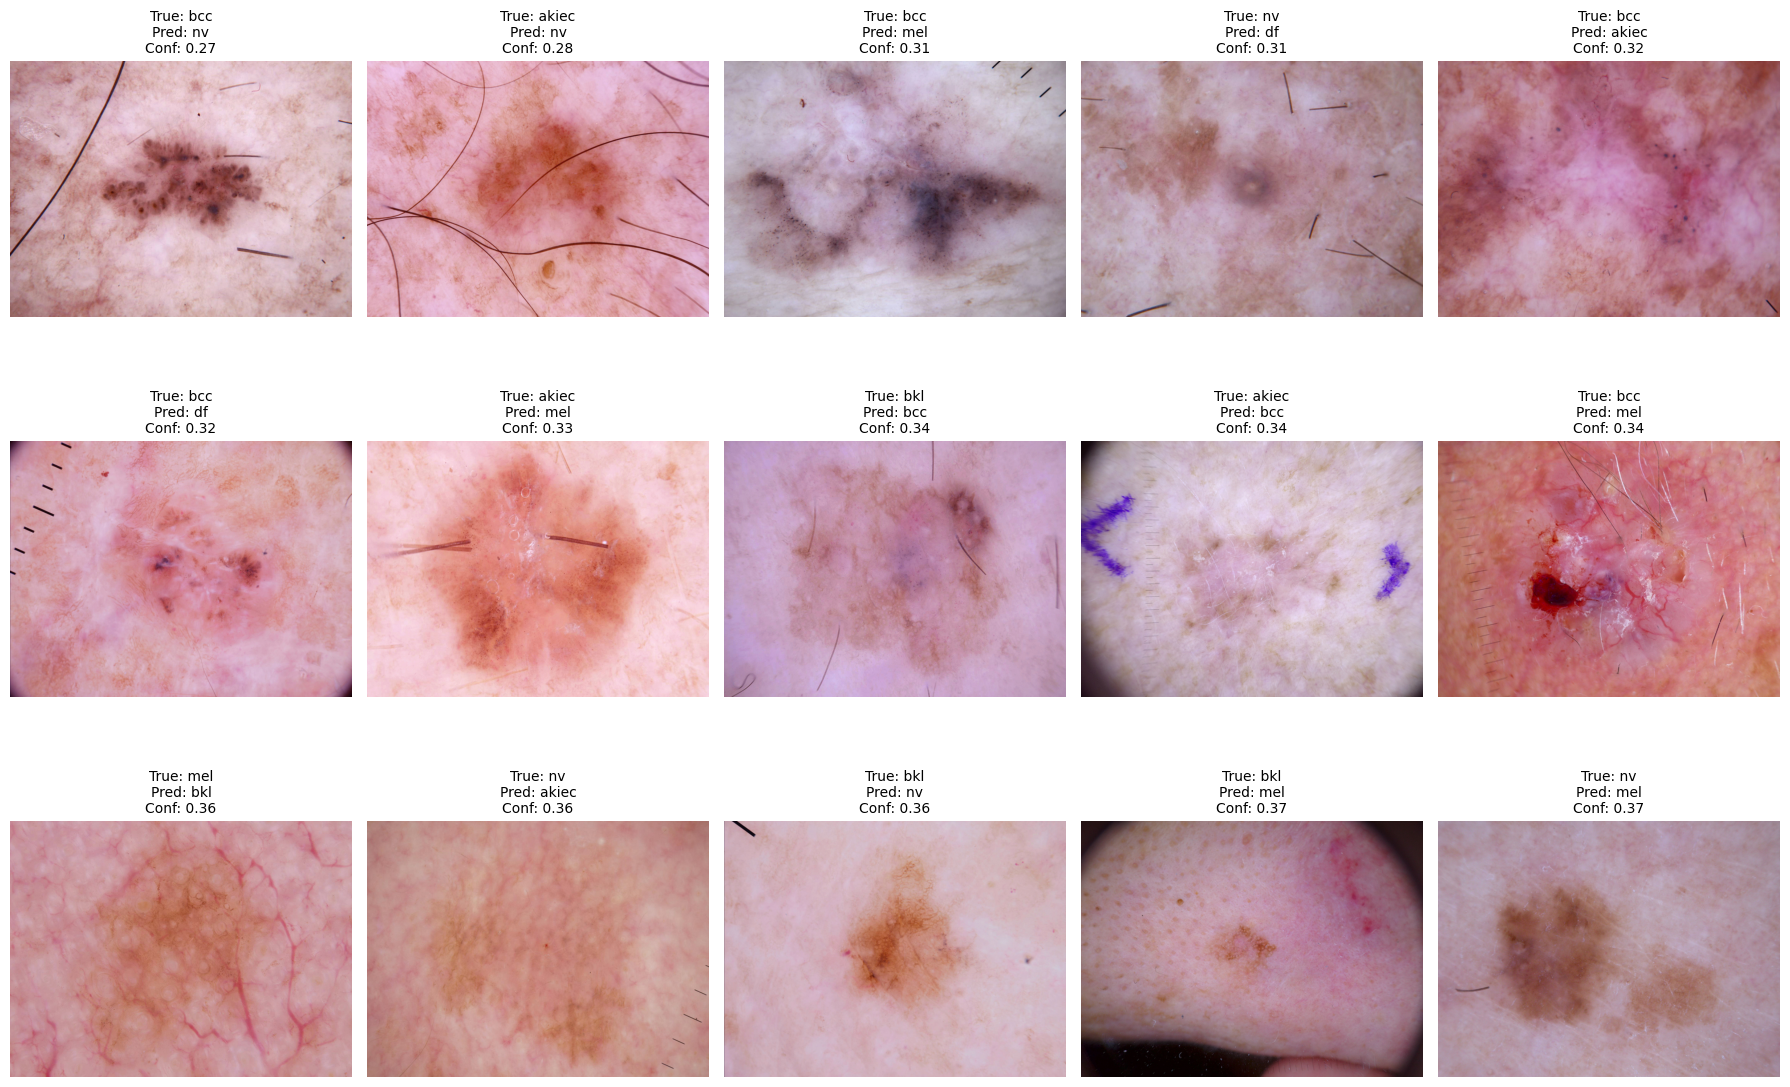

In [54]:
import matplotlib.pyplot as plt
from PIL import Image

# Use the 15 lowest-confidence validation errors
display_df = error_df[
    ["image_id", "image_path", "true_class", "pred_class", "confidence"]
].sort_values("confidence").head(15)

plt.figure(figsize=(18, 12))

for i, (_, row) in enumerate(display_df.iterrows()):
    img = Image.open(row["image_path"]).convert("RGB")

    ax = plt.subplot(3, 5, i + 1)
    ax.imshow(img)
    ax.set_title(
        f"True: {row['true_class']}\n"
        f"Pred: {row['pred_class']}\n"
        f"Conf: {row['confidence']:.2f}",
        fontsize=10
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

126/126 ━━━━━━━━━━━━━━━━━━━━ 57s 456ms/step - accuracy: 0.8248 - loss: 0.4910
126/126 ━━━━━━━━━━━━━━━━━━━━ 36s 283ms/step


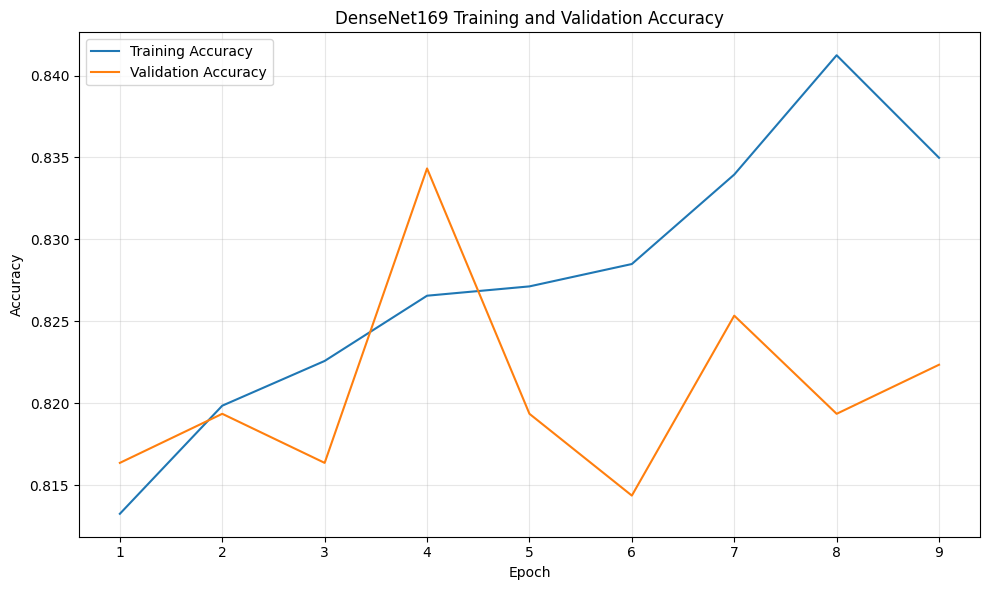

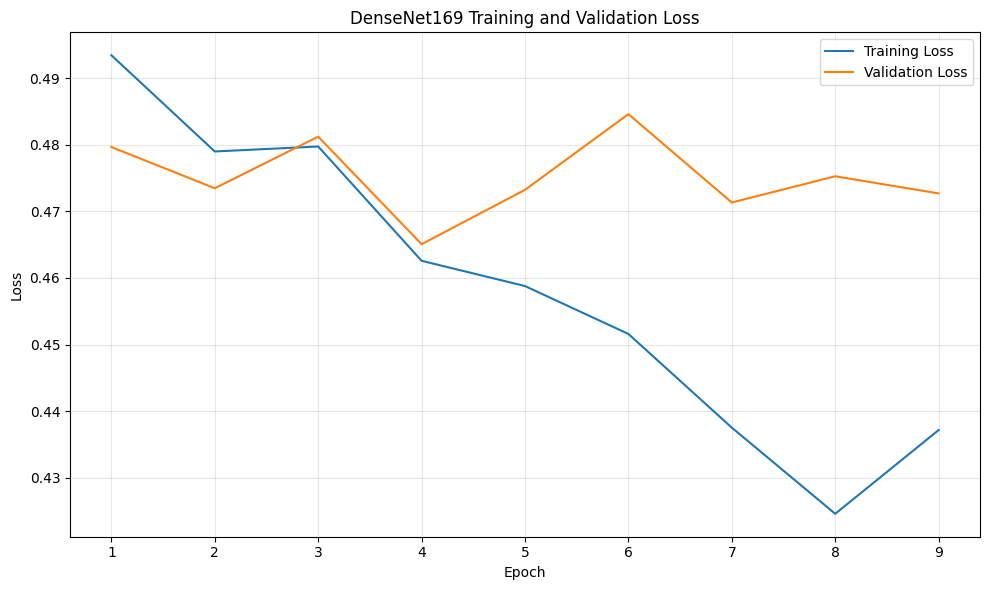

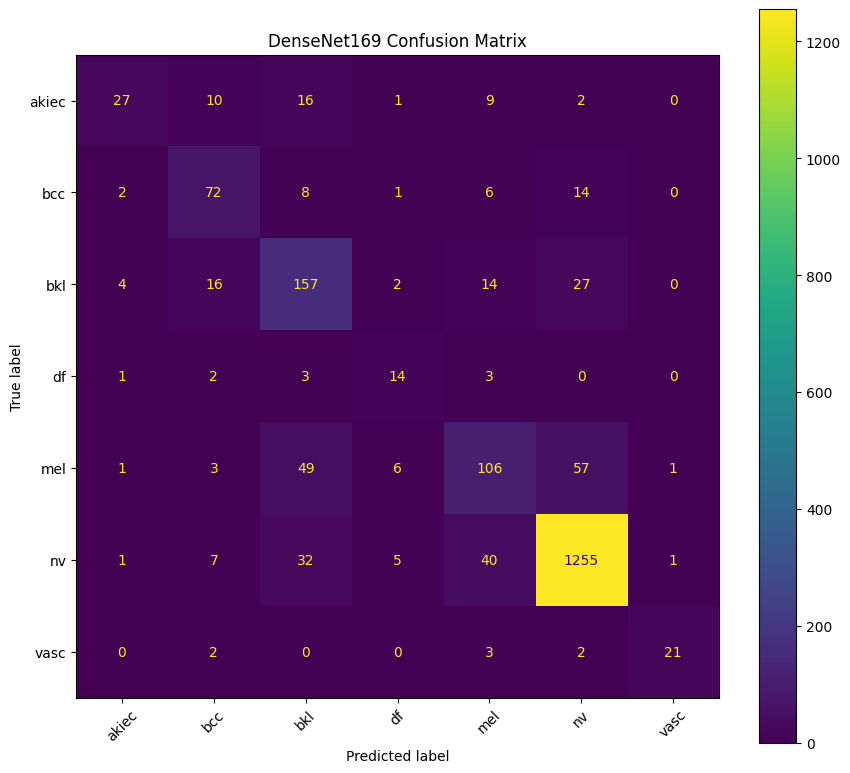


DENSENET169 - TRAINING PERFORMANCE

Total Epochs Trained        : 9
Best Epoch                  : 4
Best Training Accuracy      : 82.6567%
Best Validation Accuracy    : 83.4331%
Best Training Loss          : 0.4626
Best Validation Loss        : 0.4651

Final Training Accuracy     : 83.4982%
Final Validation Accuracy   : 82.2355%
Final Training Loss         : 0.4372
Final Validation Loss       : 0.4727


DENSENET169 - TEST PERFORMANCE

Test Loss                   : 0.4910
Test Accuracy               : 82.4763%
Number of Test Samples      : 2003


DENSENET169 - CLASSIFICATION REPORT

              precision    recall  f1-score   support

       akiec     0.7500    0.4154    0.5347        65
         bcc     0.6429    0.6990    0.6698       103
         bkl     0.5925    0.7136    0.6474       220
          df     0.4828    0.6087    0.5385        23
         mel     0.5856    0.4753    0.5248       223
          nv     0.9248    0.9359    0.9303      1341
        vasc     0.9130    0.75

In [55]:
import os
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load the best DenseNet169 model
model_exp7.load_weights(checkpoint_exp7)

# Evaluate on the untouched test set
test_generator.reset()

test_loss, test_accuracy = model_exp7.evaluate(
    test_generator,
    verbose=1
)

# Generate test predictions
test_generator.reset()

test_probs = model_exp7.predict(
    test_generator,
    verbose=1
)

test_pred = np.argmax(test_probs, axis=1)
test_true = np.asarray(test_generator.classes)

# Classification report
classification_rep = classification_report(
    test_true,
    test_pred,
    target_names=CLASS_NAMES,
    digits=4
)

# Confusion matrix
cm = confusion_matrix(
    test_true,
    test_pred
)

# Training history
best_val_acc = max(history_exp7.history["val_accuracy"])
best_epoch = np.argmax(
    history_exp7.history["val_accuracy"]
) + 1

best_train_acc = history_exp7.history["accuracy"][best_epoch - 1]
best_train_loss = history_exp7.history["loss"][best_epoch - 1]
best_val_loss = history_exp7.history["val_loss"][best_epoch - 1]

final_train_acc = history_exp7.history["accuracy"][-1]
final_train_loss = history_exp7.history["loss"][-1]
final_val_acc = history_exp7.history["val_accuracy"][-1]
final_val_loss = history_exp7.history["val_loss"][-1]

# Create output directory
report_dir = "/kaggle/working/densenet169_report"
os.makedirs(report_dir, exist_ok=True)

# Accuracy graph
epochs_range = range(
    1,
    len(history_exp7.history["accuracy"]) + 1
)

plt.figure(figsize=(10, 6))

plt.plot(
    epochs_range,
    history_exp7.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history_exp7.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("DenseNet169 Training and Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

accuracy_plot_path = os.path.join(
    report_dir,
    "densenet169_accuracy.png"
)

plt.savefig(
    accuracy_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Loss graph
plt.figure(figsize=(10, 6))

plt.plot(
    epochs_range,
    history_exp7.history["loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history_exp7.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DenseNet169 Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

loss_plot_path = os.path.join(
    report_dir,
    "densenet169_loss.png"
)

plt.savefig(
    loss_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Confusion matrix
plt.figure(figsize=(9, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

disp.plot(
    values_format="d",
    ax=plt.gca(),
    xticks_rotation=45
)

plt.title("DenseNet169 Confusion Matrix")
plt.tight_layout()

cm_plot_path = os.path.join(
    report_dir,
    "densenet169_confusion_matrix.png"
)

plt.savefig(
    cm_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# Create final text report
report_text = f"""
DENSENET169 - TRAINING PERFORMANCE

Total Epochs Trained        : {len(history_exp7.history["accuracy"])}
Best Epoch                  : {best_epoch}
Best Training Accuracy      : {best_train_acc:.4%}
Best Validation Accuracy    : {best_val_acc:.4%}
Best Training Loss          : {best_train_loss:.4f}
Best Validation Loss        : {best_val_loss:.4f}

Final Training Accuracy     : {final_train_acc:.4%}
Final Validation Accuracy   : {final_val_acc:.4%}
Final Training Loss         : {final_train_loss:.4f}
Final Validation Loss       : {final_val_loss:.4f}


DENSENET169 - TEST PERFORMANCE

Test Loss                   : {test_loss:.4f}
Test Accuracy               : {test_accuracy:.4%}
Number of Test Samples      : {len(test_true)}


DENSENET169 - CLASSIFICATION REPORT

{classification_rep}


DENSENET169 - MODEL INFORMATION

Architecture                : DenseNet169
Pretrained Weights          : ImageNet
Input Size                  : 224 x 224 x 3
Number of Classes           : 7

Training Samples            : {len(train_exp7_df)}
Validation Samples          : {len(val_df)}
Test Samples                : {len(test_df)}

Fine-Tuning Configuration   : DenseNet layers from layer 300
Trainable Backbone Layers   : 211
Frozen Backbone Layers      : 384

Best Validation Accuracy    : {best_val_acc:.4%}
Test Accuracy               : {test_accuracy:.4%}


CLASS NAMES

{CLASS_NAMES}


SAVED FILES

Accuracy Graph              : {accuracy_plot_path}
Loss Graph                  : {loss_plot_path}
Confusion Matrix            : {cm_plot_path}
Model Checkpoint            : {checkpoint_exp7}
"""

# Save report
report_path = os.path.join(
    report_dir,
    "densenet169_final_report.txt"
)

with open(report_path, "w") as f:
    f.write(report_text)

# Display report
print(report_text)

print("Report saved to:")
print(report_path)

print("\nGraphs saved in:")
print(report_dir)

In [59]:
report_text = f"""
DENSENET169 - TRAINING PERFORMANCE

Total Epochs Trained       : {len(history_exp7.history["accuracy"])}
Best Epoch                 : {best_epoch}
Training Accuracy          : {best_train_acc:.4%}
Validation Accuracy        : {best_val_acc:.4%}
Training Loss              : {best_train_loss:.4f}
Validation Loss            : {best_val_loss:.4f}


DENSENET169 - TEST PERFORMANCE

Test Loss                  : {test_loss:.4f}
Test Accuracy              : {test_accuracy:.4%}


DENSENET169 - CLASSIFICATION REPORT

{classification_rep}


DENSENET169 - MODEL INFORMATION

Architecture               : DenseNet169
Pretrained Weights         : ImageNet
Input Size                 : 224 x 224 x 3
Number of Classes          : 7

Training Samples           : {len(train_exp7_df)}
Validation Samples         : {len(val_df)}
Test Samples               : {len(test_df)}

Fine-Tuning Configuration  : DenseNet layers from layer 300
Trainable Backbone Layers  : 211
Frozen Backbone Layers     : 384

Best Validation Accuracy   : {best_val_acc:.4%}
Test Accuracy              : {test_accuracy:.4%}


CLASS NAMES

{CLASS_NAMES}


SAVED FILES

Accuracy Graph             : {accuracy_plot_path}
Loss Graph                 : {loss_plot_path}
Confusion Matrix           : {cm_plot_path}
Model Checkpoint           : {checkpoint_exp7}
"""